# 01 · Replication of the thesis analysis (Python)

**Thesis:** *Determinants of Healthcare Access in the United States: A Synthesis of Literature Evidence and NHIS Data* (HTM692)
**Data:** 2024 National Health Interview Survey (NHIS), Sample Adult file (`Data/adult24csv.zip`)

This notebook re-creates, without SAS, every regression in the thesis (Tables 2-9) with a survey-weighted
logistic / proportional-odds engine (`nhis_survey.py`) that mirrors `PROC SURVEYLOGISTIC`:

* weight `WTFA_A`, strata `PSTRAT`, clusters `PPSU`; Taylor-series (Binder) variance; t-based CIs with df = #PSU - #strata
* identical recodes to Appendix A of the thesis, identical reference categories

Sections: (1) design and recodes, (2) side-by-side check against the thesis tables, (3) the outcome-direction problem,
(4) the thesis figures re-drawn as run, and re-drawn with the correct direction.
Notebook **02** carries out the corrected analysis that the manuscript will use.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from nhis_survey import *
from thesis_tables import parse_tables
from validate_port import compare, label_to_key
import plots
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:.3f}".format)
T = parse_tables()          # thesis Tables 2-9 as printed in the .docx

## 1 · Data, recodes and survey design

In [2]:
raw = load_adult()
d = recode(raw)
n_psu = d.groupby(["PSTRAT", "PPSU"]).ngroups
print(f"Adults in file          : {len(d):,}")
print(f"Weighted population     : {d.WTFA_A.sum()/1e6:,.1f} million")
print(f"Strata / PSUs / df      : {d.PSTRAT.nunique()} / {n_psu} / {n_psu - d.PSTRAT.nunique()}")
print(f"Mean / max weight       : {d.WTFA_A.mean():,.0f} / {d.WTFA_A.max():,.0f}")

Adults in file          : 32,629
Weighted population     : 259.7 million
Strata / PSUs / df      : 52 / 662 / 610
Mean / max weight       : 7,958 / 38,138


In [3]:
def wprop(df, var, labels=None):
    s = df[[var, "WTFA_A"]].dropna()
    t = s.groupby(var).WTFA_A.agg(["size", "sum"])
    t["n"] = t["size"]; t["weighted %"] = 100 * t["sum"] / t["sum"].sum()
    t = t[["n", "weighted %"]]
    if labels: t.index = [labels.get(i, i) for i in t.index]
    return t

outcomes = {
    "HINOTYR_A":  ("Insurance continuity", {1: "Yes", 2: "No"}),
    "MEDDL12M_A": ("Delayed care (cost)", {1: "Yes", 2: "No"}),
    "MEDNG12M_A": ("Unmet care (cost)", {1: "Yes", 2: "No"}),
    "TRANSPOR_A": ("Transportation barrier", {1: "Yes", 2: "No"}),
    "RXDG12M_A":  ("Unmet prescription (cost)", {1: "Yes", 2: "No"}),
}
for v, (nm, lab) in outcomes.items():
    print(f"--- {v}: {nm}")
    display(wprop(d, v, lab))

--- HINOTYR_A: Insurance continuity


,n,weighted %
Yes,1096,4.233
No,29230,95.767


--- MEDDL12M_A: Delayed care (cost)


,n,weighted %
Yes,2564,8.579
No,29791,91.421


--- MEDNG12M_A: Unmet care (cost)


,n,weighted %
Yes,2195,7.387
No,30159,92.613


--- TRANSPOR_A: Transportation barrier


,n,weighted %
Yes,1899,6.080
No,29323,93.920


--- RXDG12M_A: Unmet prescription (cost)


,n,weighted %
Yes,1953,6.305
No,30355,93.695


## 2 · Side-by-side check against the thesis tables

`compare()` lines up each Python odds ratio and 95% CI with the value printed in the thesis. Tables 2 and 6-9 are binary
models with `event="2 No"` (the SAS code in Appendix A). Tables 3-5 were fit with SAS's default for a multi-level response, the
**cumulative-logit (proportional-odds) model**, so they are replicated as ordinal models.

In [4]:
binary_jobs = {2: ("HINOTYR_A", 2), 6: ("MEDDL12M_A", 2), 7: ("MEDNG12M_A", 2), 8: ("TRANSPOR_A", 2), 9: ("RXDG12M_A", 2)}
asrun, summary = {}, []

def summarize(tno, y, model, info, dd):
    return dict(Table=tno, outcome=y, model=model, n_python=info["n"], rows=len(dd),
                max_abs_dOR=dd.dOR.abs().max(), max_abs_dLo=dd.dlo.abs().max(), max_abs_dHi=dd.dhi.abs().max(),
                p_sign_agree=int(((dd.p_py < .05) == (dd.p_thesis < .05)).sum()))

for tno, (y, ev) in binary_jobs.items():
    res, info = svy_logit(d, y, ev)
    asrun[tno] = res
    dd = compare(T[tno], res, f"Table {tno} [{y}, event={ev}]")
    summary.append(summarize(tno, y, f"binary logit, event={ev}", info, dd))

Table 2 [HINOTYR_A, event=2]: rows=29  max|dOR|=0.0005  max|dlo|=0.0011  max|dhi|=0.0012


Table 6 [MEDDL12M_A, event=2]: rows=29  max|dOR|=0.0012  max|dlo|=0.0012  max|dhi|=0.0007


Table 7 [MEDNG12M_A, event=2]: rows=29  max|dOR|=0.0016  max|dlo|=0.0020  max|dhi|=0.0020


Table 8 [TRANSPOR_A, event=2]: rows=29  max|dOR|=0.0005  max|dlo|=0.0007  max|dhi|=0.0007


Table 9 [RXDG12M_A, event=2]: rows=29  max|dOR|=0.0005  max|dlo|=0.0005  max|dhi|=0.0008


In [5]:
# Tables 3-5: proportional-odds models on multi-level responses (what SAS did by default)
s3 = d[(d.HINOTYR_A == 2) & d.COVER_A.isin([1, 2, 3])]                      # thesis Table 3
res3, i3 = svy_ordinal(s3, "COVER_A");                      dd3 = compare(T[3], res3, "Table 3 [COVER_A | HINOTYR_A=2, levels 1-3]")
s4 = d[(d.HINOTYR_A == 2) & (d.AGE_CAT == 4)]                                # thesis Table 4
res4, i4 = svy_ordinal(s4, "COVER65_A", predictors=[p for p in PREDICTORS if p != "AGE_CAT"]); dd4 = compare(T[4], res4, "Table 4 [COVER65_A | HINOTYR_A=2, 65+]")
res5, i5 = svy_ordinal(d, "USUALPL_A");                     dd5 = compare(T[5], res5, "Table 5 [USUALPL_A]")
asrun.update({3: res3, 4: res4, 5: res5})
summary += [summarize(3, "COVER_A", "ordinal logit", i3, dd3), summarize(4, "COVER65_A", "ordinal logit", i4, dd4),
            summarize(5, "USUALPL_A", "ordinal logit", i5, dd5)]
S = pd.DataFrame(summary).sort_values("Table").set_index("Table")
S.to_csv("results/replication_summary.csv")
display(S)

Table 3 [COVER_A | HINOTYR_A=2, levels 1-3]: rows=29  max|dOR|=0.0007  max|dlo|=0.0139  max|dhi|=4.1611


Table 4 [COVER65_A | HINOTYR_A=2, 65+]: rows=26  max|dOR|=0.0004  max|dlo|=0.0354  max|dhi|=0.0610


Table 5 [USUALPL_A]: rows=29  max|dOR|=0.0005  max|dlo|=0.0049  max|dhi|=0.0097


,outcome,model,n_python,rows,max_abs_dOR,max_abs_dLo,max_abs_dHi,p_sign_agree
Table,,,,,,,,
2,HINOTYR_A,"binary logit, event=2",28946,29,0.000,0.001,0.001,29
3,COVER_A,ordinal logit,17445,29,0.001,0.014,4.161,28
4,COVER65_A,ordinal logit,10313,26,0.000,0.035,0.061,25
5,USUALPL_A,ordinal logit,31044,29,0.000,0.005,0.010,29
6,MEDDL12M_A,"binary logit, event=2",31057,29,0.001,0.001,0.001,29
7,MEDNG12M_A,"binary logit, event=2",31061,29,0.002,0.002,0.002,29
8,TRANSPOR_A,"binary logit, event=2",31008,29,0.000,0.001,0.001,29
9,RXDG12M_A,"binary logit, event=2",31053,29,0.000,0.001,0.001,29


**Reading the table.** `max_abs_dOR` is the largest absolute difference between a Python and a thesis odds ratio over all rows of the table
(the thesis prints two decimals, so differences up to about 0.005 are rounding). `p_sign_agree` counts rows where the significance call at 0.05 agrees.
Notes: (i) Table 3 reproduces only when the uninsured level (`COVER_A = 4`) is dropped, i.e. a three-level response with `n = 17,445` rather than the 17,580 printed; (ii) point estimates of the ordinal models agree to three decimals, but my ordinal standard errors differ from SAS by about 3%, which moves a few borderline p-values across 0.05 (Table 3 `FDSCAT4_A` Low vs High: 0.037 vs 0.052; Table 4 `PHSTAT_A` Fair vs Very Good: 0.0496 vs 0.0505); (iii) the large upper-CI gap in Table 3 is the `AGE_CAT` 65+ row, which rests on only 24 respondents (an unstable estimate in any software). None of this matters for the manuscript, because Tables 3-5 are re-specified in notebook 02.

In [6]:
def side_by_side(tno, res, ref_p=0.05):
    r = res.set_index(["var", "level"])
    rows = []
    for t in T[tno]:
        k = (t["var"], label_to_key(t["var"], t["label"]))
        m = r.loc[k]
        rows.append({"variable": t["var"], "contrast": t["label"], "thesis OR": t["OR"], "thesis CI": f'{t["lo"]:.2f}-{t["hi"]:.2f}',
                     "python OR": m.OR, "python CI": f"{m.lo:.2f}-{m.hi:.2f}", "thesis p": t["p"], "python p": m.p})
    return pd.DataFrame(rows)
display(Markdown("**Table 7 (unmet care due to cost), thesis vs Python**"))
display(side_by_side(7, asrun[7]))

**Table 7 (unmet care due to cost), thesis vs Python**

,variable,contrast,thesis OR,thesis CI,python OR,python CI,thesis p,python p
0,POV_CAT,2–5 FPL vs <2 FPL,0.800,0.69-0.93,0.800,0.69-0.93,0.003,0.003
1,POV_CAT,>5 FPL vs <2 FPL,1.557,1.25-1.93,1.557,1.26-1.93,0.000,0.000
2,FDSCAT4_A,Marginal vs High,0.446,0.37-0.54,0.446,0.37-0.54,0.000,0.000
3,FDSCAT4_A,Low vs High,0.250,0.21-0.30,0.250,0.21-0.30,0.000,0.000
4,FDSCAT4_A,Very low vs High,0.183,0.15-0.22,0.183,0.15-0.22,0.000,0.000
5,HOUTENURE_A,Rented vs Owned,0.842,0.73-0.96,0.842,0.73-0.97,0.014,0.014
6,HOUTENURE_A,Other vs Owned,0.848,0.57-1.25,0.848,0.57-1.25,0.408,0.408
7,REGION,Northeast vs South,1.573,1.31-1.90,1.573,1.31-1.89,0.000,0.000
8,REGION,Midwest vs South,1.281,1.09-1.51,1.281,1.09-1.51,0.003,0.003
9,REGION,West vs South,1.230,1.05-1.45,1.230,1.05-1.45,0.012,0.012


## 3 · The outcome-direction problem

In every binary model the SAS code used `event="2 No"`, i.e. the odds of **no** barrier (for `MEDDL12M_A`, `MEDNG12M_A`, `TRANSPOR_A`, `RXDG12M_A`,
code 2 = "No"). So an OR < 1 means *higher* odds of the barrier. The thesis text for Table 6 handled this correctly (it reported reciprocals), but the text for
Tables 7-9, Figure 3 (forest plots) and Figure 4 (heatmap) read the ORs as odds *of* the barrier. Refitting with `event=1` ("Yes") shows the exact relationship:
OR(barrier) = 1 / OR(no barrier), with the CI limits swapped and p unchanged.

In [7]:
bar_vars = {6: "MEDDL12M_A", 7: "MEDNG12M_A", 8: "TRANSPOR_A", 9: "RXDG12M_A"}
fit_no, fit_yes = {}, {}
for tno, y in bar_vars.items():
    fit_no[tno], _ = svy_logit(d, y, 2)       # as run in the thesis: odds of NO barrier
    fit_yes[tno], _ = svy_logit(d, y, 1)      # explicit: odds of the barrier
    fit_no[tno], fit_yes[tno] = plots._clean(fit_no[tno]), plots._clean(fit_yes[tno])   # drop intercept row
    gap = (fit_yes[tno].OR - 1 / fit_no[tno].OR).abs().max()
    gap_lo = (fit_yes[tno].lo - 1 / fit_no[tno].hi).abs().max()
    print(f"Table {tno} {y}: max |OR_yes - 1/OR_no| = {gap:.2e};  max |lo_yes - 1/hi_no| = {gap_lo:.2e}")

Table 6 MEDDL12M_A: max |OR_yes - 1/OR_no| = 3.55e-15;  max |lo_yes - 1/hi_no| = 3.11e-15


Table 7 MEDNG12M_A: max |OR_yes - 1/OR_no| = 4.88e-15;  max |lo_yes - 1/hi_no| = 5.33e-15


Table 8 TRANSPOR_A: max |OR_yes - 1/OR_no| = 5.77e-15;  max |lo_yes - 1/hi_no| = 5.33e-15


Table 9 RXDG12M_A: max |OR_yes - 1/OR_no| = 8.88e-15;  max |lo_yes - 1/hi_no| = 7.99e-15


In [8]:
# Which thesis conclusions flip? Significant rows, as the thesis read them vs what they mean
rows = []
for tno, y in bar_vars.items():
    f = fit_no[tno].copy(); fy = fit_yes[tno]
    f["OR_barrier"] = fy.OR.values; f["lo_barrier"] = fy.lo.values; f["hi_barrier"] = fy.hi.values
    f["label"] = [plots.row_label(v, l, r) for v, l, r in zip(f["var"], f.level, f.ref)]
    f["Table"] = tno; rows.append(f[f.p < .05])
flip = pd.concat(rows)[["Table", "label", "OR", "lo", "hi", "OR_barrier", "lo_barrier", "hi_barrier", "p"]]
flip["thesis reading"] = np.where(flip.OR > 1, "higher odds of barrier", "lower odds of barrier")
flip["correct reading"] = np.where(flip.OR_barrier > 1, "higher odds of barrier", "lower odds of barrier")
flip["conclusion reversed?"] = flip["thesis reading"] != flip["correct reading"]
flip.to_csv("results/direction_check_significant_rows.csv", index=False)
print("Significant predictors:", len(flip), "| of which read in the wrong direction when the ORs are taken at face value (Tables 7-9):",
      int(flip[flip.Table > 6]["conclusion reversed?"].sum()), "of", int((flip.Table > 6).sum()))
display(flip.rename(columns={"OR": "OR (event=No)", "lo": "lo", "hi": "hi"}).set_index(["Table", "label"]))

Significant predictors: 74 | of which read in the wrong direction when the ORs are taken at face value (Tables 7-9): 51 of 51


OR (event=No)    lo    hi  OR_barrier  lo_barrier  hi_barrier     p          thesis reading         correct reading  \
Table label                                                                                                                                                            
6     Income: 2–<5× FPL vs <2× FPL                       0.767 0.666 0.883       1.303       1.132       1.501 0.000   lower odds of barrier  higher odds of barrier   
      Income: ≥5× FPL vs <2× FPL                         1.478 1.216 1.797       0.676       0.557       0.822 0.000  higher odds of barrier   lower odds of barrier   
      Food security: Marginal vs High                    0.457 0.383 0.544       2.189       1.837       2.610 0.000   lower odds of barrier  higher odds of barrier   
      Food security: Low vs High                         0.294 0.246 0.351       3.406       2.850       4.072 0.000   lower odds of barrier  higher odds of barrier   
      Food security: Very low vs High                    0.189 0.156 0.230       5.285       4.357       6.410 0.000   lower odds of barrier  higher odds of barrier   
...                                                        ...   ...   ...         ...         ...         ...   ...                     ...                     ...   
9     Age: ≥65 vs 50–64                                  1.897 1.590 2.262       0.527       0.442       0.629 0.000  higher odds of barrier   lower odds of barrier   
      Self-rated health: Excellent vs Very good          1.698 1.350 2.136       0.589       0.468       0.741 0.000  higher odds of barrier   lower odds of barrier   
      Self-rated health: Good vs Very good               0.688 0.586 0.807       1.454       1.239       1.707 0.000   lower odds of barrier  higher odds of barrier   
      Self-rated health: Fair vs Very good               0.425 0.352 0.513       2.353       1.948       2.841 0.000   lower odds of barrier  higher odds of barrier   
      Self-rated health: Poor vs Very good               0.316 0.243 0.411       3.167       2.436       4.118 0.000   lower odds of barrier  higher odds of barrier   

                                                 conclusion reversed?  
Table label                                                            
6     Income: 2–<5× FPL vs <2× FPL                               True  
      Income: ≥5× FPL vs <2× FPL                                 True  
      Food security: Marginal vs High                            True  
      Food security: Low vs High                                 True  
      Food security: Very low vs High                            True  
...                                                               ...  
9     Age: ≥65 vs 50–64                                          True  
      Self-rated health: Excellent vs Very good                  True  
      Self-rated health: Good vs Very good                       True  
      Self-rated health: Fair vs Very good                       True  
      Self-rated health: Poor vs Very good                       True  

[74 rows x 10 columns]

## 4 · Figures, as run and with the correct direction

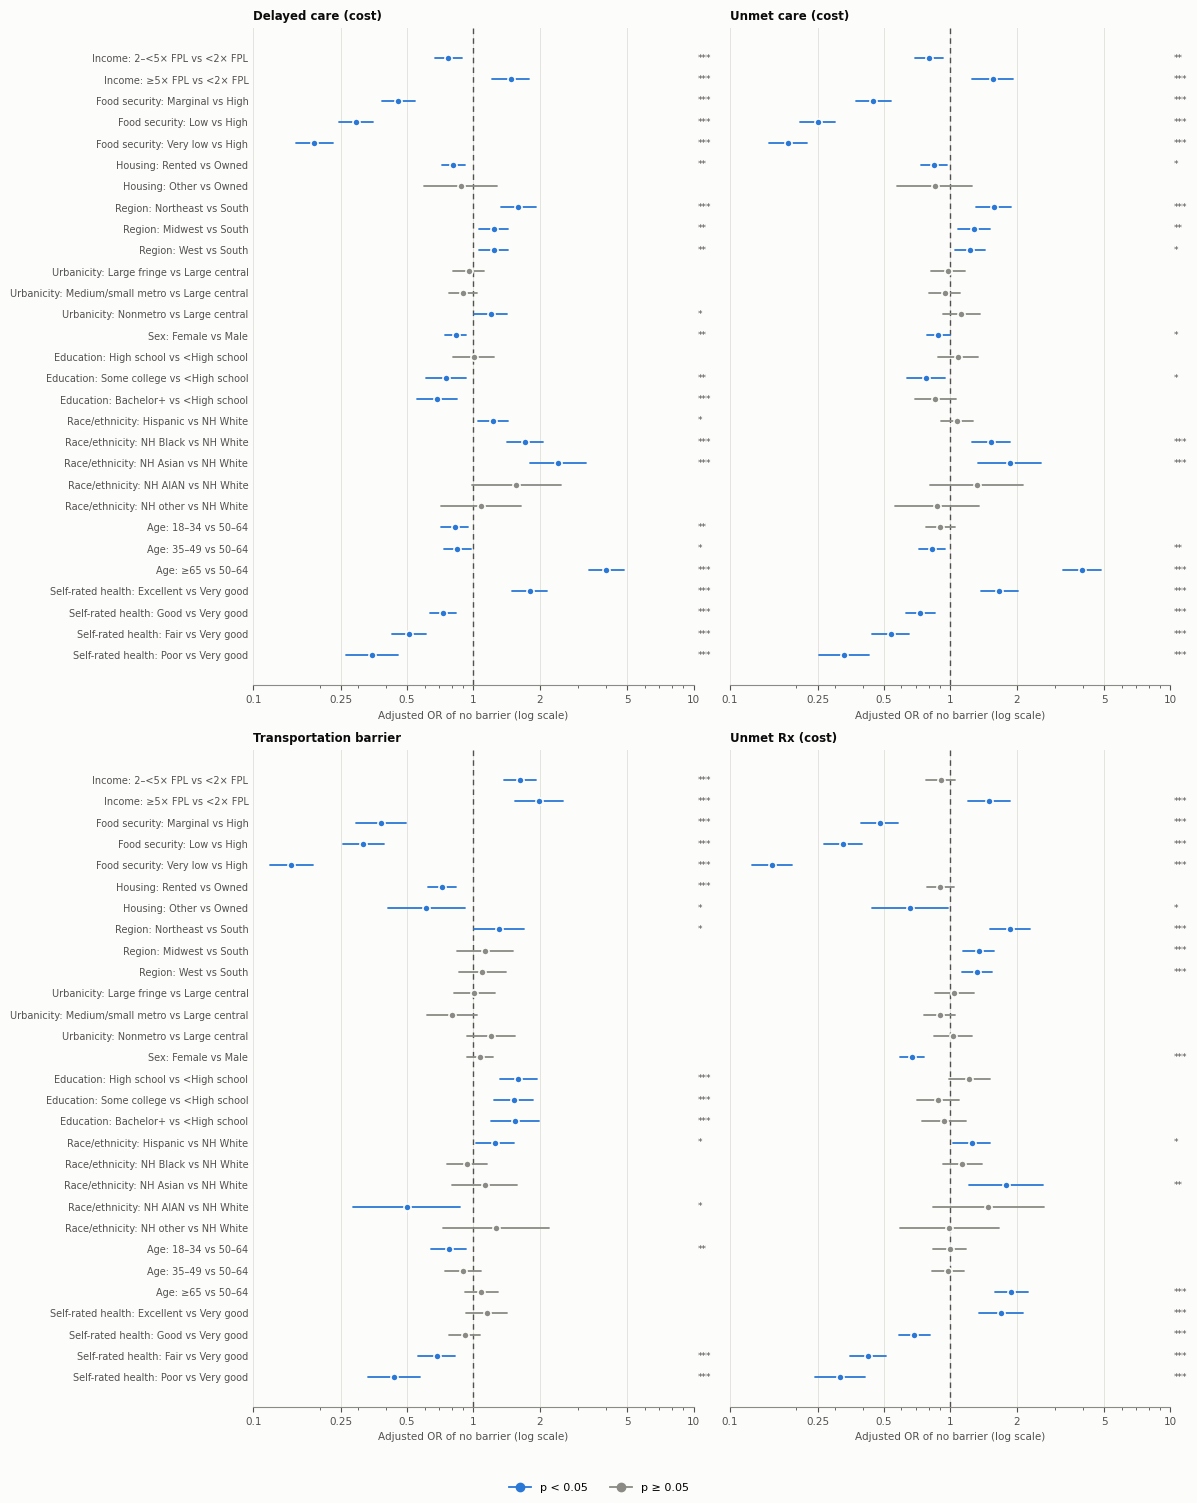

In [9]:
titles_asrun = {6: "Delayed care (cost)", 7: "Unmet care (cost)", 8: "Transportation barrier", 9: "Unmet Rx (cost)"}
fig = plots.forest_panels({k: fit_no[k] for k in bar_vars}, titles_asrun, ncols=2, figsize=(12, 15),
                          suptitle="As run in the thesis: adjusted odds of NO barrier (OR < 1 = MORE barrier)",
                          xlabel="Adjusted OR of no barrier (log scale)", outfile="figures/fig3_forest_as_run.png")
plt.show()

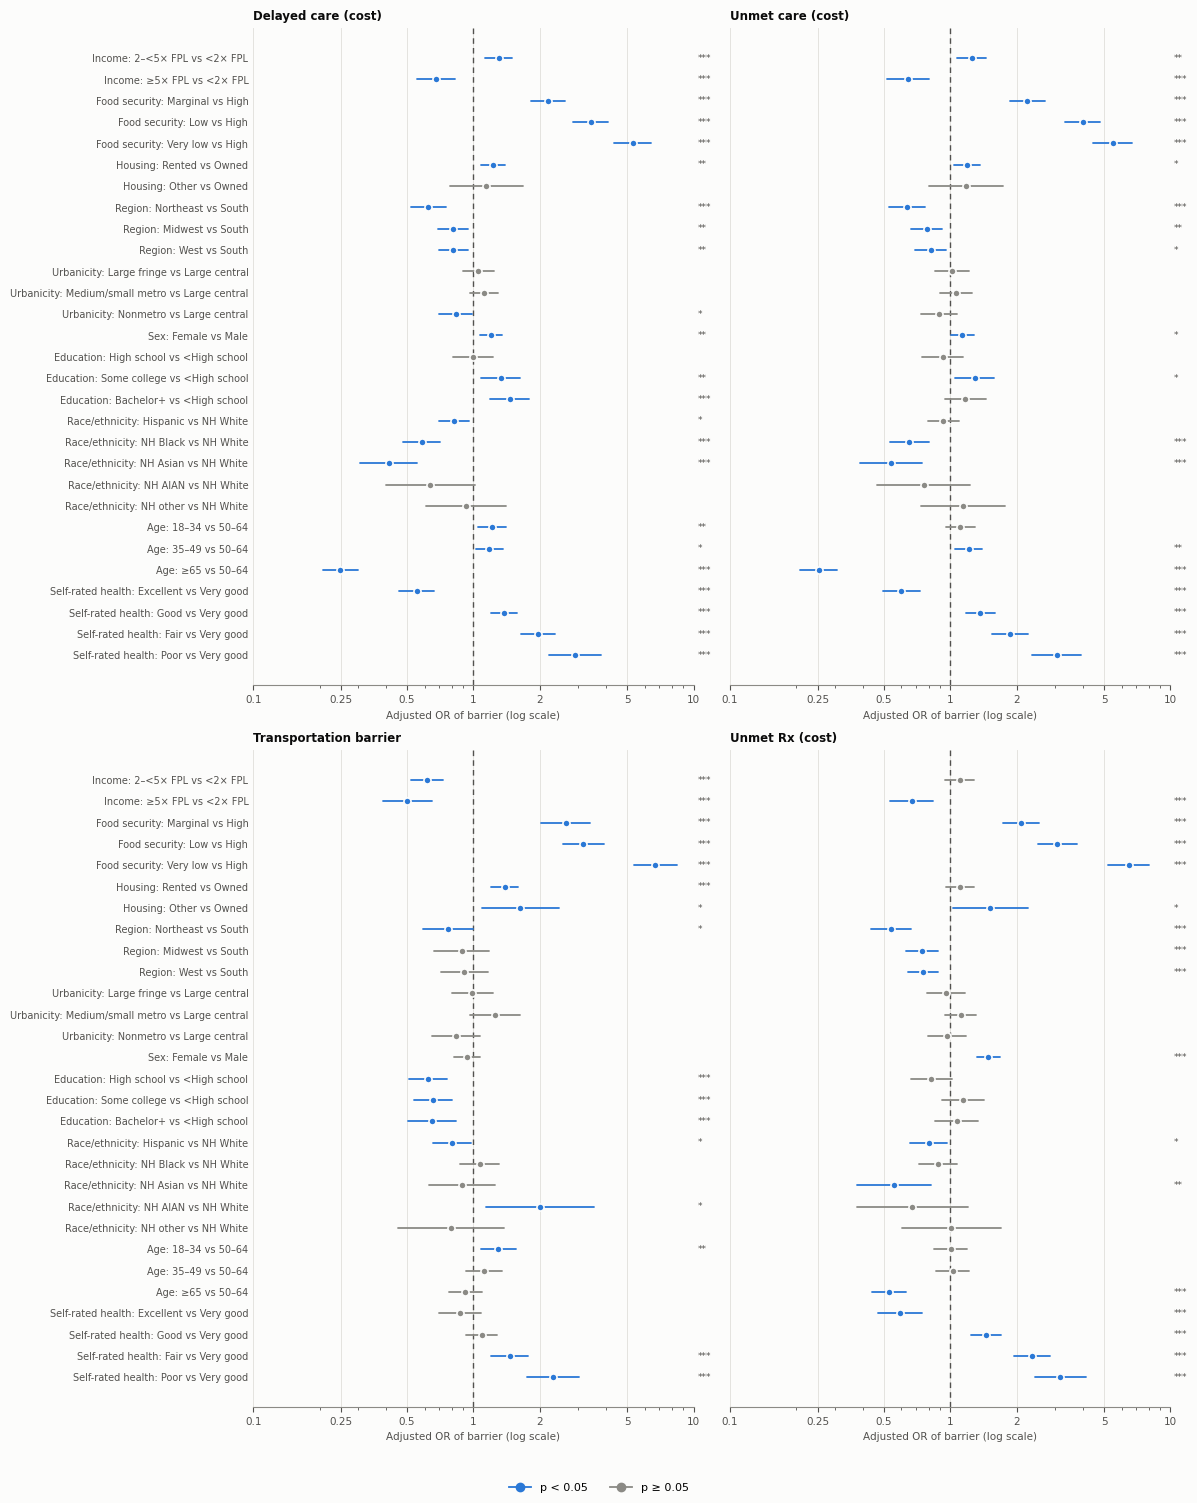

In [10]:
fig = plots.forest_panels({k: fit_yes[k] for k in bar_vars}, titles_asrun, ncols=2, figsize=(12, 15),
                          suptitle="Corrected direction: adjusted odds of the barrier (OR > 1 = MORE barrier)",
                          xlabel="Adjusted OR of barrier (log scale)", outfile="figures/fig3_forest_barrier_direction.png")
plt.show()

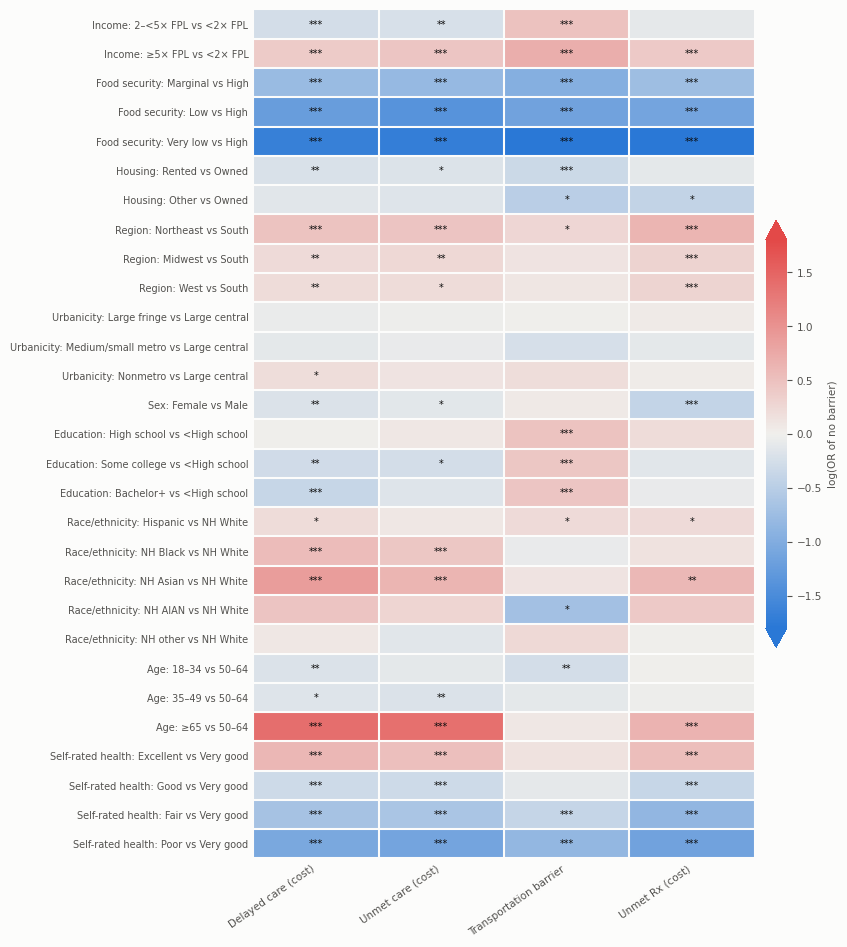

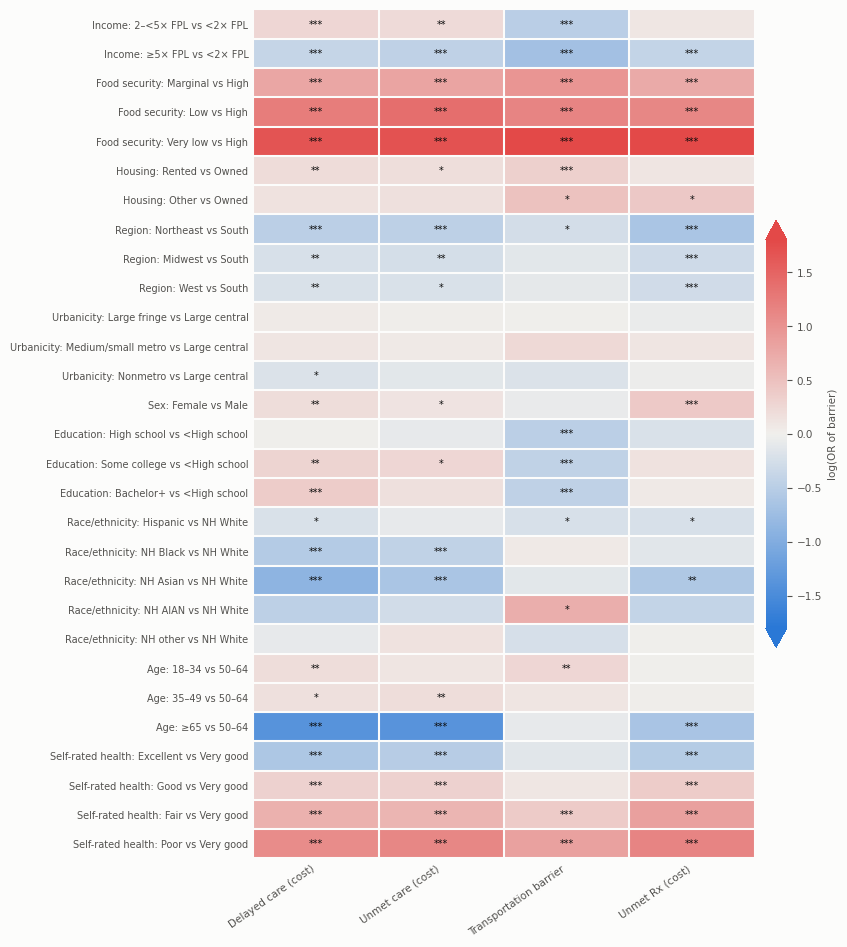

In [11]:
plots.heatmap({k: fit_no[k] for k in bar_vars}, titles_asrun, suptitle="As run: log(OR of NO barrier)  [blue = more barrier]",
              cbar_label="log(OR of no barrier)", outfile="figures/fig4_heatmap_as_run.png"); plt.show()
plots.heatmap({k: fit_yes[k] for k in bar_vars}, titles_asrun, suptitle="Corrected: log(OR of barrier)  [red = more barrier]",
              cbar_label="log(OR of barrier)", outfile="figures/fig4_heatmap_barrier_direction.png"); plt.show()

**Takeaways for the manuscript**

1. The Python engine reproduces the thesis odds ratios (to rounding) for all eight tables, so the analysis is replicable without SAS.
2. The direction of Tables 7-9 / Figures 3-4 has to be reversed (or the models refit with `event="Yes"`) before any claim is carried into the manuscript.
3. Tables 3-5 are ordinal models on insurance type / usual place of care and the "insurance continuity" outcome is defined only among the currently insured;
   these need re-specification, which is done in notebook 02.